<a href="https://colab.research.google.com/github/rodrigoviannasn/MAT-422/blob/main/MAT422_HW_3_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 — Homework 3.2: Limits, Derivatives, and Taylor's Theorem

Rodrigo Vianna | 10/11/2026

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial

np.set_printoptions(precision=6, suppress=True)

## 3.2.1 Limits and Continuity

Consider the function

$$
f(x)=\frac{x^2-4}{x-2}, \qquad x \ne 2.
$$

Factoring the numerator gives

$$
f(x)=\frac{(x-2)(x+2)}{x-2}=x+2, \qquad x \ne 2.
$$

Even though $f(2)$ is undefined, the values of $f(x)$ approach $4$ as $x$ approaches $2$. Therefore,

$$
\lim_{x\to 2} f(x)=4.
$$

The function has a removable discontinuity at $x=2$. Defining $g(2)=4$ creates a continuous extension of the function.

Values approaching from the left:
x = 1.9000, f(x) = 3.9000
x = 1.9900, f(x) = 3.9900
x = 1.9990, f(x) = 3.9990
x = 1.9999, f(x) = 3.9999

Values approaching from the right:
x = 2.1000, f(x) = 4.1000
x = 2.0100, f(x) = 4.0100
x = 2.0010, f(x) = 4.0010
x = 2.0001, f(x) = 4.0001

Limit as x approaches 2: 4
Is f(2) defined in the original function? No
Does the continuous extension satisfy g(2) = limit? True


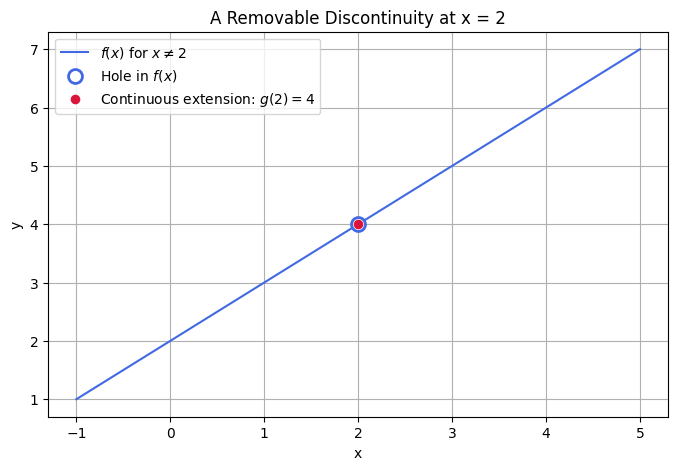

In [7]:
left_points = np.array([1.9, 1.99, 1.999, 1.9999])
right_points = np.array([2.1, 2.01, 2.001, 2.0001])

# For x ≠ 2, the original expression simplifies to x + 2.
left_values = left_points + 2
right_values = right_points + 2

limit_value = 4
continuous_extension_value = 2 + 2

print("Values approaching from the left:")
for x_value, f_value in zip(left_points, left_values):
    print(f"x = {x_value:.4f}, f(x) = {f_value:.4f}")

print("\nValues approaching from the right:")
for x_value, f_value in zip(right_points, right_values):
    print(f"x = {x_value:.4f}, f(x) = {f_value:.4f}")

print("\nLimit as x approaches 2:", limit_value)
print("Is f(2) defined in the original function? No")
print(
    "Does the continuous extension satisfy g(2) = limit?",
    bool(np.isclose(continuous_extension_value, limit_value))
)

x_left = np.linspace(-1, 1.99, 250)
x_right = np.linspace(2.01, 5, 250)

plt.figure(figsize=(8, 5))
plt.plot(x_left, x_left + 2, color="royalblue", label=r"$f(x)$ for $x \ne 2$")
plt.plot(x_right, x_right + 2, color="royalblue")

# Open circle shows that f is not defined at x = 2.
plt.scatter(
    2, 4,
    s=100,
    facecolors="white",
    edgecolors="royalblue",
    linewidths=2,
    zorder=3,
    label=r"Hole in $f(x)$"
)

# Filled point represents the continuous extension g(2) = 4.
plt.scatter(
    2, 4,
    s=35,
    color="crimson",
    zorder=4,
    label=r"Continuous extension: $g(2)=4$"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("A Removable Discontinuity at x = 2")
plt.grid()
plt.legend()
plt.show()

### Section Conclusion

The values from both sides approached $4$, so the limit exists even though the original function is undefined at $x=2$. The open circle on the graph represents the discontinuity. Adding the value $g(2)=4$ fills the hole and makes the function continuous.

## 3.2.2 Derivatives

For the function

$$
h(x)=x^3-2x^2+x,
$$

the derivative is

$$
h'(x)=3x^2-4x+1.
$$

The derivative gives the instantaneous rate of change, or the slope of the tangent line. This example compares the exact derivative at $x=2$ with a numerical approximation found using the central-difference formula:

$$
h'(a)\approx\frac{h(a+\Delta x)-h(a-\Delta x)}{2\Delta x}.
$$

Function value at x = 2: 2.0
Exact derivative at x = 2: 5.0
Numerical derivative at x = 2: 5.000000000165983
Do the exact and numerical derivatives agree? True


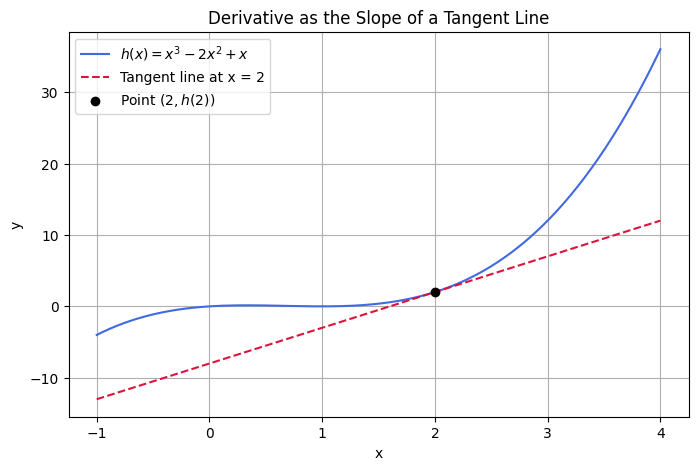

In [8]:
def h(x):
    return x**3 - 2*x**2 + x

def h_derivative(x):
    return 3*x**2 - 4*x + 1

a = 2.0
step_size = 1e-5

exact_slope = h_derivative(a)
numerical_slope = (
    h(a + step_size) - h(a - step_size)
) / (2 * step_size)

tangent_intercept = h(a) - exact_slope * a

print("Function value at x = 2:", h(a))
print("Exact derivative at x = 2:", exact_slope)
print("Numerical derivative at x = 2:", numerical_slope)
print(
    "Do the exact and numerical derivatives agree?",
    bool(np.isclose(exact_slope, numerical_slope, atol=1e-5))
)

x_values = np.linspace(-1, 4, 500)
tangent_line = h(a) + exact_slope * (x_values - a)

plt.figure(figsize=(8, 5))
plt.plot(x_values, h(x_values), color="royalblue", label=r"$h(x)=x^3-2x^2+x$")
plt.plot(
    x_values,
    tangent_line,
    color="crimson",
    linestyle="--",
    label=f"Tangent line at x = {a:g}"
)
plt.scatter(a, h(a), color="black", zorder=3, label=r"Point $(2, h(2))$")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Derivative as the Slope of a Tangent Line")
plt.grid()
plt.legend()
plt.show()

### Section Conclusion

The exact derivative and the numerical derivative were nearly identical, which verifies the central-difference approximation. At $x=2$, the derivative is positive, so the function is increasing there. The dashed line on the graph has the same slope as the curve at the selected point.

## 3.2.3 Taylor's Theorem

Taylor's theorem approximates a function near a chosen center using a polynomial. In general,

$$
f(x)=P_n(x)+R_n(x),
$$

where $P_n(x)$ is the Taylor polynomial of degree $n$ and $R_n(x)$ is the remainder term.

For $f(x)=e^x$ centered at $x=0$, the Taylor polynomial is

$$
P_n(x)=\sum_{k=0}^{n}\frac{x^k}{k!}.
$$

This example compares Taylor polynomials of degrees $1$, $3$, and $5$ with the actual function $e^x$.

Actual value of e^1: 2.71828183

Degree-1 approximation: 2.00000000
Absolute error: 0.71828183

Degree-3 approximation: 2.66666667
Absolute error: 0.05161516

Degree-5 approximation: 2.71666667
Absolute error: 0.00161516



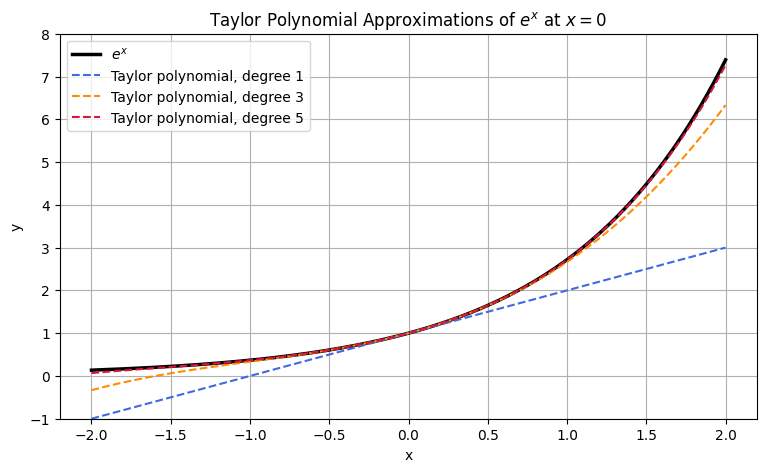

In [9]:
def taylor_exp(x, degree):
    x = np.asarray(x)
    approximation = np.zeros_like(x, dtype=float)

    for k in range(degree + 1):
        approximation += x**k / factorial(k)

    return approximation

test_x = 1.0
actual_value = np.exp(test_x)
degrees = [1, 3, 5]

print(f"Actual value of e^{test_x:g}: {actual_value:.8f}\n")

for degree in degrees:
    approximation = float(taylor_exp(test_x, degree))
    absolute_error = abs(actual_value - approximation)

    print(f"Degree-{degree} approximation: {approximation:.8f}")
    print(f"Absolute error: {absolute_error:.8f}\n")

x_values = np.linspace(-2, 2, 500)

plt.figure(figsize=(9, 5))
plt.plot(x_values, np.exp(x_values), color="black", linewidth=2.5, label=r"$e^x$")

colors = ["royalblue", "darkorange", "crimson"]

for degree, color in zip(degrees, colors):
    plt.plot(
        x_values,
        taylor_exp(x_values, degree),
        color=color,
        linestyle="--",
        label=f"Taylor polynomial, degree {degree}"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Taylor Polynomial Approximations of $e^x$ at $x=0$")
plt.ylim(-1, 8)
plt.grid()
plt.legend()
plt.show()

### Section Conclusion

The Taylor polynomials gave increasingly accurate approximations of $e^x$ at $x=1$ as the degree increased. On the graph, the approximations are closest to $e^x$ near the center $x=0$. This shows how derivative information at one point can be used to estimate function values nearby.

## Conclusion / Reflection

Working through these examples made the connection between the topics clearer to me. Limits describe what happens as a function gets close to a value, and derivatives build on limits to measure how quickly a function changes. Taylor's theorem then uses derivatives to create a simpler polynomial approximation of a more complicated function.

The visual examples were especially useful. The graph with the hole showed that a limit can exist even when the function is not defined at that exact point. The tangent line helped show what a derivative represents, and the Taylor graph showed why higher-degree approximations can be more accurate near the center point. Overall, this homework helped me see how these calculus concepts relate to each other instead of viewing them as separate formulas.